### Импорт итогового датасета

In [ ]:
%pip install matplotlib==3.11.2 pandas==3.1.0 seaborn scikit-learn

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

df=pd.read_csv('key_rate_dataset.csv')

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110


### Анализ длины и кол-ва пресс-релизов

Детальнее посмотрим на сам корпус пресс-релизов.


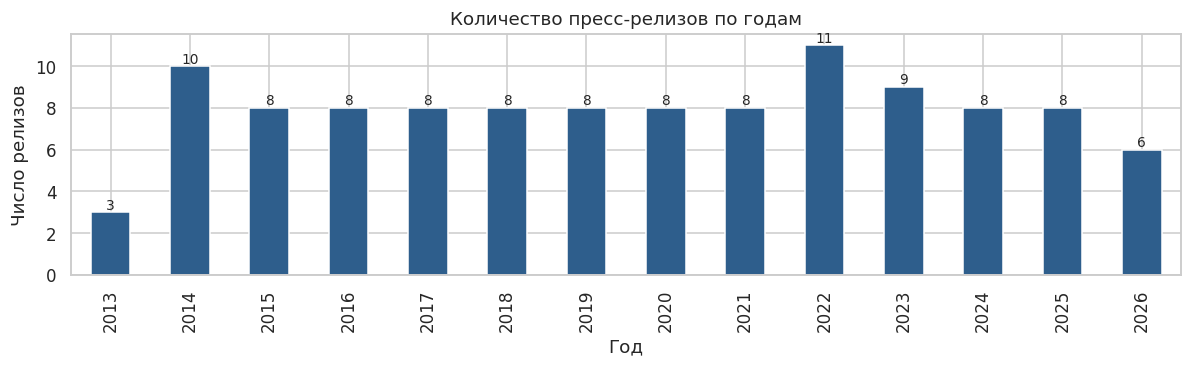

In [8]:
# Кол-во релизов по годам

per_year = df.groupby("year").size()
fig, ax = plt.subplots(figsize=(11, 3.5))
per_year.plot(kind="bar", ax=ax, color="#2E5E8C")
ax.set_title("Количество пресс-релизов по годам")
ax.set_xlabel("Год")
ax.set_ylabel("Число релизов")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

Стандартно проводится 8 заседаний в год. Отклонения (10 в 2014, 11 в 2022, 9 в 2023) соответствуют периодам кризисов и внеплановых заседаний, что свидетельствует о зависимости целевой переменной от макроэкономической эпохи. Количество заседаний в год можно использовать как отдельный признак при обучении.

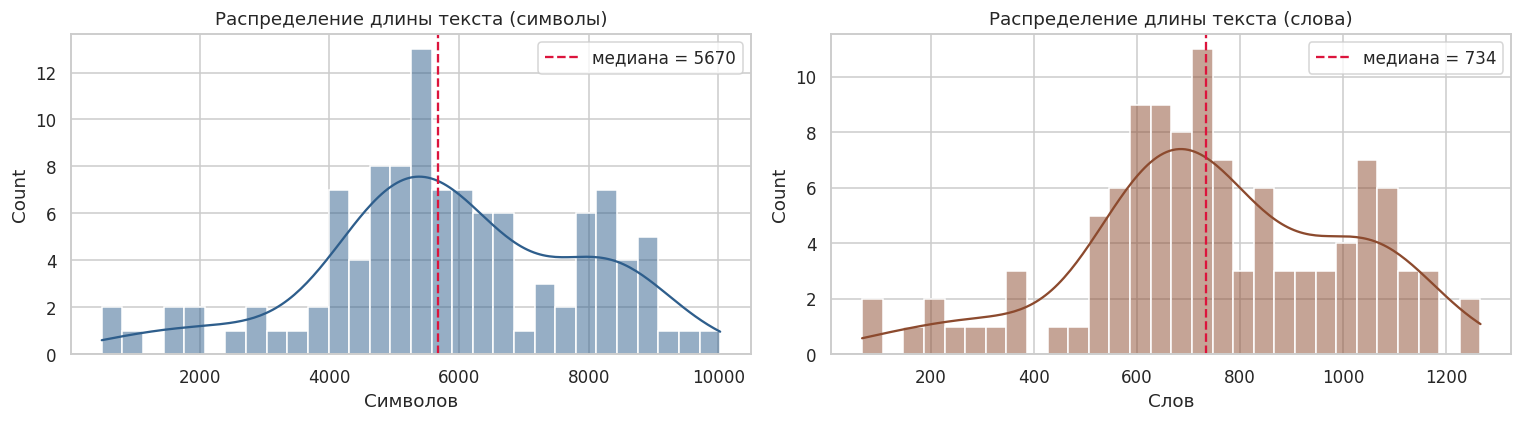

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Символы
sns.histplot(df["len_chars"], bins=30, kde=True, ax=axes[0], color="#2E5E8C")
axes[0].set_title("Распределение длины текста (символы)")
axes[0].set_xlabel("Символов")
axes[0].axvline(df["len_chars"].median(), color="crimson", ls="--",
                label=f"медиана = {df['len_chars'].median():.0f}")
axes[0].legend()

# Слова
sns.histplot(df["len_words"], bins=30, kde=True, ax=axes[1], color="#8C4A2E")
axes[1].set_title("Распределение длины текста (слова)")
axes[1].set_xlabel("Слов")
axes[1].axvline(df["len_words"].median(), color="crimson", ls="--",
                label=f"медиана = {df['len_words'].median():.0f}")
axes[1].legend()

plt.tight_layout()
plt.show()


Распределение двухмодальное, в корпусе смешано два формата текстов. Медиана — 5670 символов (734 слова).

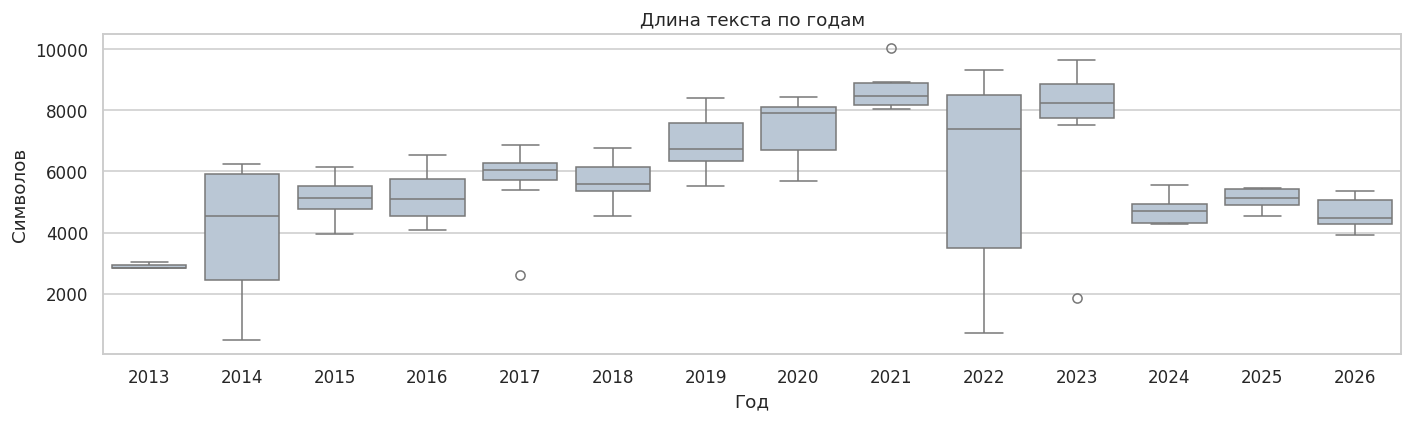

In [10]:
fig, ax = plt.subplots(figsize=(13, 4))
sns.boxplot(data=df, x="year", y="len_chars", ax=ax, color="#B5C7DA")
ax.set_title("Длина текста по годам")
ax.set_xlabel("Год")
ax.set_ylabel("Символов")
plt.tight_layout()
plt.show()

Прослеживается временной тренд длины текста:

С 2013 по 2021 год тексты постепенно становились всё длиннее (от 3000 до 8000+ символов).

В 2022 году случился огромный разброс (boxplot очень широкий) — были и экстренные короткие релизы (~1000 символов), и стандартные длинные.

С 2023 года формат резко изменился: тексты стали короче и стабильнее (~4000–5000 символов).

### Анализ таргета


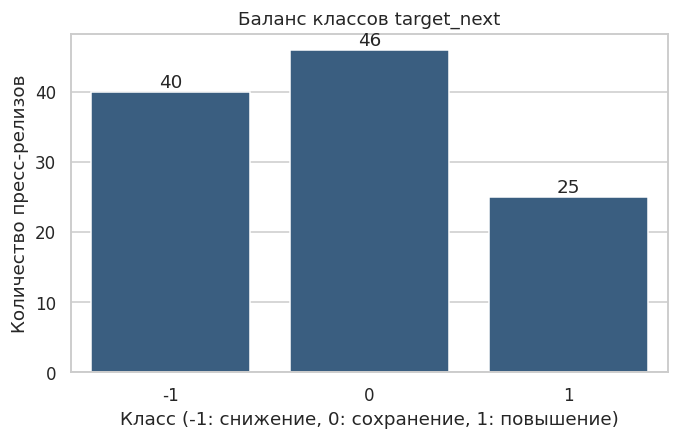

In [11]:
class_counts = df['target_next'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, color='#2E5E8C', ax=ax)
ax.set_title("Баланс классов target_next")
ax.set_xlabel("Класс (-1: снижение, 0: сохранение, 1: повышение)")
ax.set_ylabel("Количество пресс-релизов")

for p, v in zip(ax.patches, class_counts.values):
    ax.annotate(v, (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')

plt.show()

Классы не являются идеально сбалансированными, наблюдается умеренный дисбаланс. Самый частый класс (0) встречается более чем в два раза чаще самого редкого класса (1).

Оценивать качество модели только по метрике accuracy в данном случае будет некорректно. Обязательно нужно смотреть на Macro F1-score, Recall и Precision.



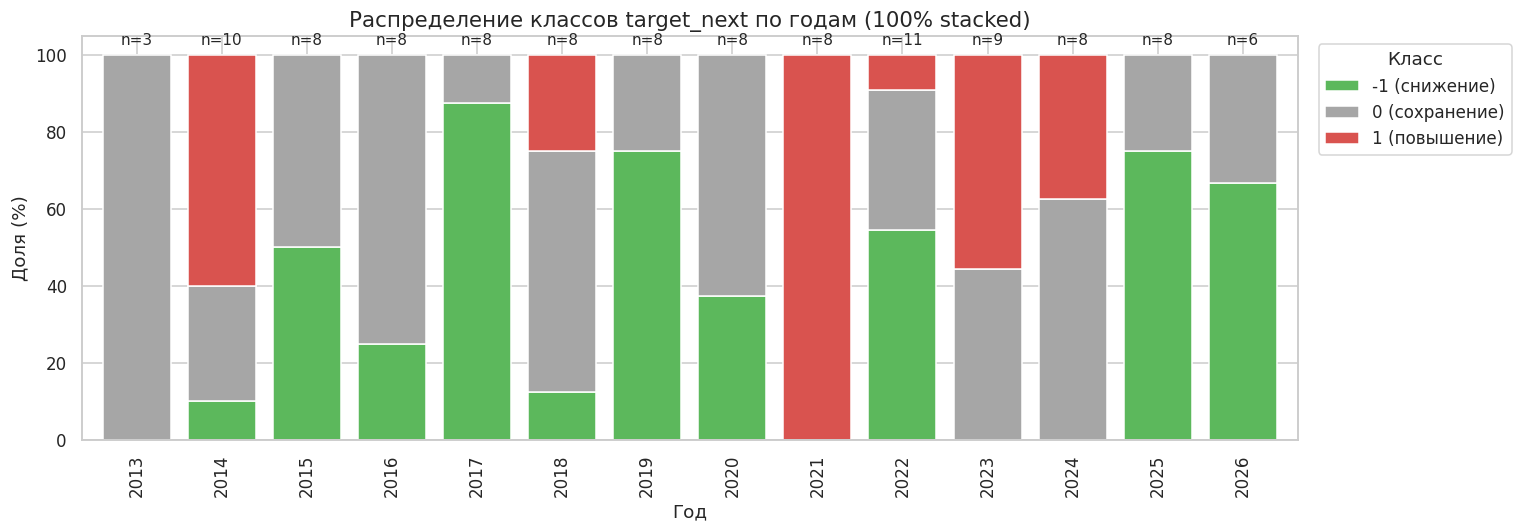

In [12]:
ct = pd.crosstab(df['year'], df['target_next'])
ct_norm = ct.div(ct.sum(axis=1), axis=0) * 100
colors = ['#5cb85c', '#a6a6a6', '#d9534f']

fig, ax = plt.subplots(figsize=(14, 5))
ct_norm.plot(kind='bar', stacked=True, color=colors, ax=ax, width=0.8)

ax.set_title('Распределение классов target_next по годам (100% stacked)', fontsize=14)
ax.set_xlabel('Год', fontsize=12)
ax.set_ylabel('Доля (%)', fontsize=12)
ax.legend(title='Класс', labels=['-1 (снижение)', '0 (сохранение)', '1 (повышение)'],
          bbox_to_anchor=(1.01, 1), loc='upper left')

for i, year in enumerate(ct.index):
    total = ct.loc[year].sum()
    ax.text(i, 102, f'n={total}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

Распределение классов по годам показывает явный временной сдвиг.
Модель, обученная на ранних годах, может хуже работать на более поздних, если поведение ЦБ и формулировки пресс-релизов меняются. Поэтому для проверки качества предпочтительно временное разделение на train/test, а не случайное перемешивание.

/tmp/ipykernel_676/939590876.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


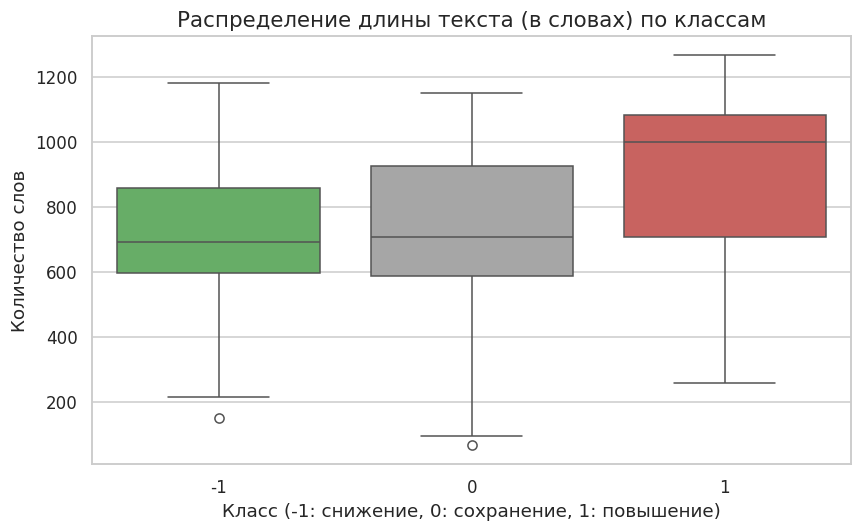

Медианная длина текста (в словах) по классам:
target_next
-1     690.5
 0     707.5
 1    1000.0
Name: len_words, dtype: float64


In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='target_next',
    y='len_words',
    palette=colors,
    ax=ax
)

ax.set_title('Распределение длины текста (в словах) по классам', fontsize=14)
ax.set_xlabel('Класс (-1: снижение, 0: сохранение, 1: повышение)', fontsize=12)
ax.set_ylabel('Количество слов', fontsize=12)

plt.tight_layout()
plt.show()

print("Медианная длина текста (в словах) по классам:")
print(df.groupby('target_next')['len_words'].median())

Длина текста не различает классы снижения и сохранения, но может являтся значимым признаком для класса повышения

/tmp/ipykernel_676/2604904648.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


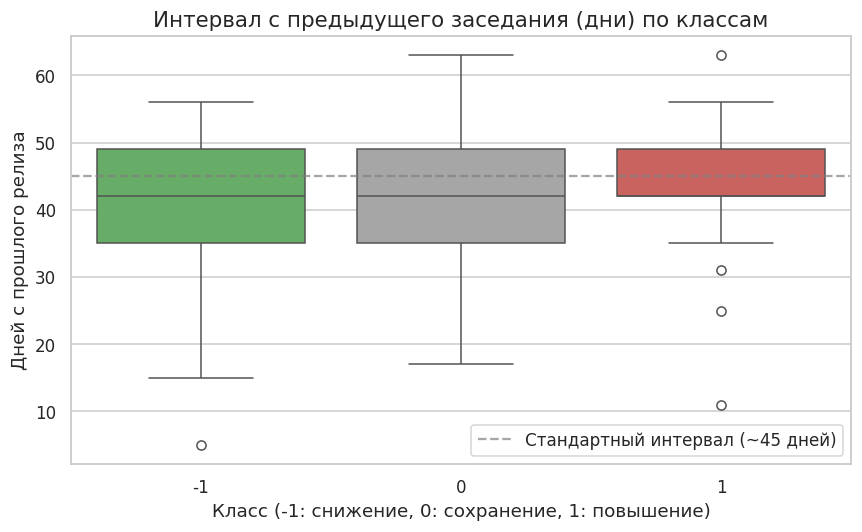

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='target_next',
    y='days_since_prev',
    palette=colors,
    ax=ax
)

ax.set_title('Интервал с предыдущего заседания (дни) по классам', fontsize=14)
ax.set_xlabel('Класс (-1: снижение, 0: сохранение, 1: повышение)', fontsize=12)
ax.set_ylabel('Дней с прошлого релиза', fontsize=12)

# Добавим горизонтальную линию стандартного интервала (~45 дней)
ax.axhline(45, color='gray', linestyle='--', alpha=0.7, label='Стандартный интервал (~45 дней)')
ax.legend()

plt.tight_layout()
plt.show()

Короткие интервалы чаще встречаются перед изменением ставки, а именно перед повышением. Внеплановые заседания и как следствие короткие интервалы между ними говорят о нестабильной экономической обстановке.

### Семантический анализ

Семантический анализ здесь основан на TF-IDF: каждому слову или биграмме присваивается вес с учётом частоты в документе и редкости во всём корпусе. Затем для каждого класса вычисляется разница между средним TF-IDF внутри класса и вне него.

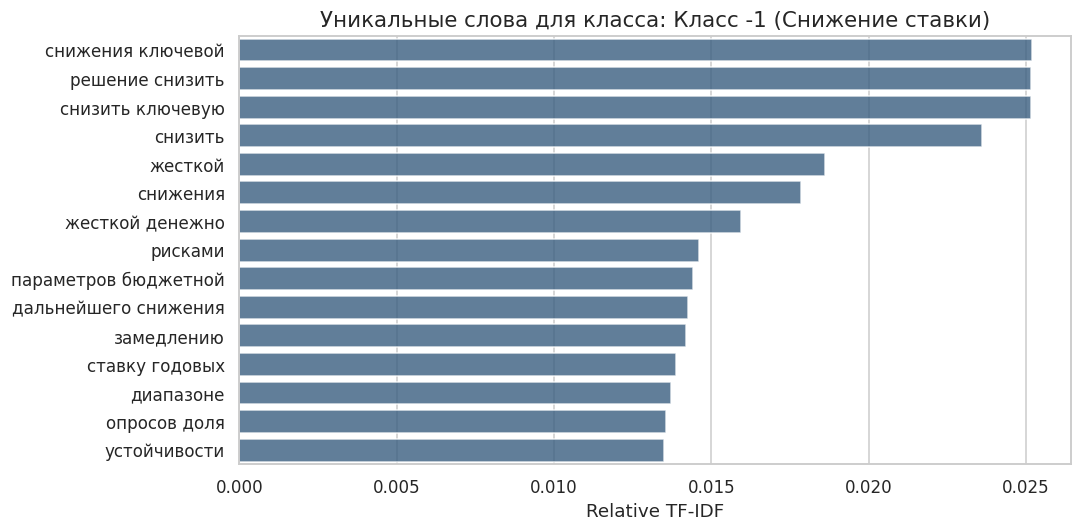

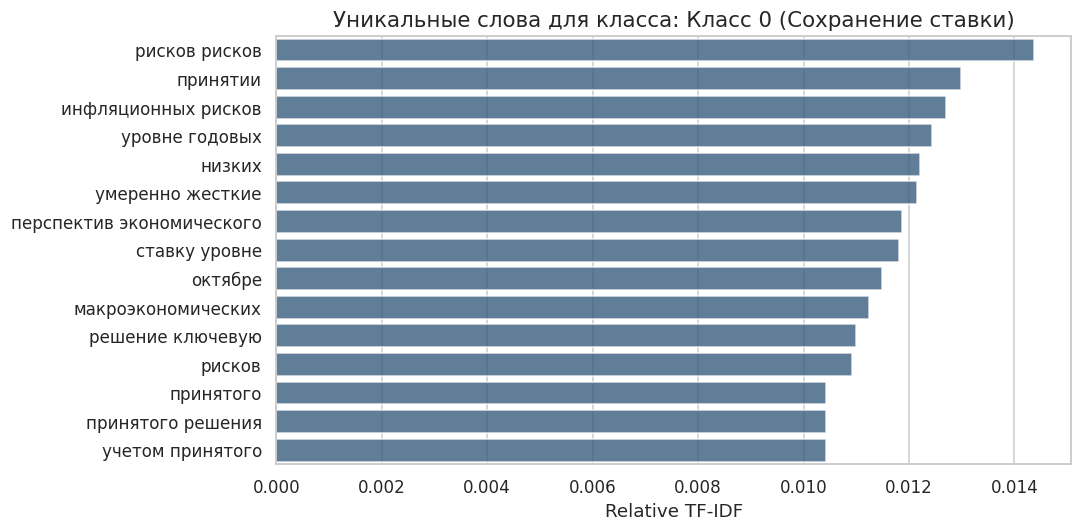

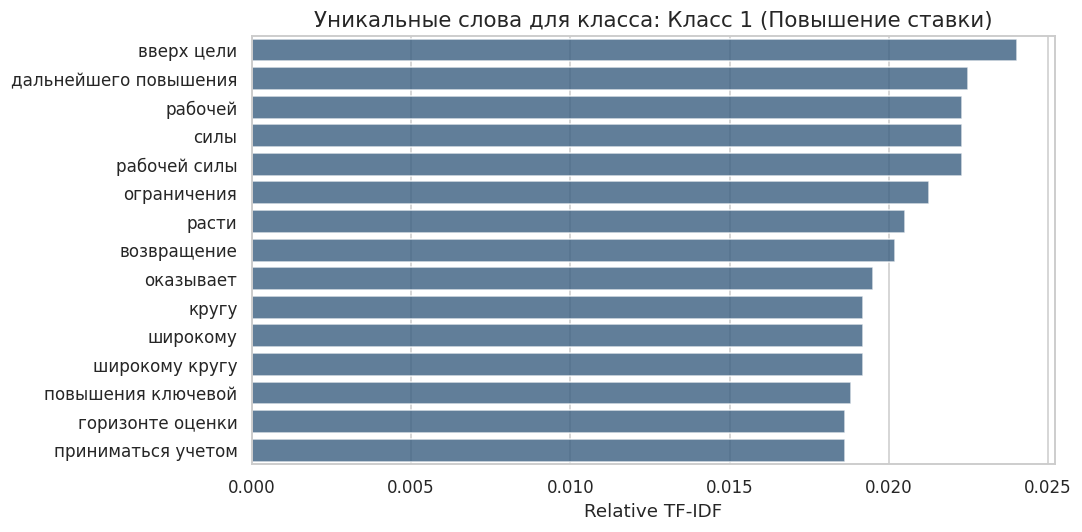

In [16]:
# Расширенный список стоп-слов (добавляем предлоги и местоимения)
basic_stopwords = ['на', 'по', 'до', 'в', 'с', 'за', 'из', 'от', 'для', 'при', 'об', 'о', 'не', 'что', 'как', 'это', 'или', 'но', 'а', 'же', 'ли', 'бы', 'его', 'ее', 'их', 'над', 'под', 'без']
custom_stop_words = [
    'россии', 'россия', 'банка', 'банк', 'года', 'год', 'также', 'этом', 'который',
    'которая', 'которые', 'будет', 'были', 'более', 'менее', 'может', 'только',
    'через', 'после', 'чтобы', 'если', 'своих', 'своей', 'около', 'связи', 'всего',
    'набиуллиной', 'эльвиры', 'председателя', 'совета', 'директоров', 'заседания',
    'пресс', 'службу', 'ссылку', 'pdf', 'сохранить', 'копировать', 'материала'
] + basic_stopwords

df = df.dropna(subset=['text_clean', 'target_next']).reset_index(drop=True)

# Настраиваем векторизатор
vectorizer = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2),
    stop_words=custom_stop_words,
    token_pattern=r'(?u)\b[А-Яа-яЁё]{4,}\b',
    sublinear_tf=True
)


# Векторизуем
X = vectorizer.fit_transform(df['text_clean'])
feature_names = vectorizer.get_feature_names_out()

# Вычисляем уникальность (Relative TF-IDF)
# Для каждого класса считаем: (средний TF-IDF в классе) - (средний TF-IDF в остальных)
classes = [-1, 0, 1]
class_titles = {
    -1: 'Класс -1 (Снижение ставки)',
     0: 'Класс 0 (Сохранение ставки)',
     1: 'Класс 1 (Повышение ставки)'
}

for cls in classes:
    # Проверяем наличие документов обоих типов
    mask_class = (df['target_next'] == cls).to_numpy()
    mask_other = ~mask_class

    if not mask_class.any():
        print(f'Класс {cls} отсутствует в данных. Пропускаем.')
        continue

    if not mask_other.any():
        print(f'Нет документов других классов для сравнения с классом {cls}.')
        continue

    # Средний TF-IDF для этого класса и для остальных
    mean_tfidf_class = np.asarray(X[mask_class].mean(axis=0)).flatten()
    mean_tfidf_other = np.asarray(X[mask_other].mean(axis=0)).flatten()

    # Разница (насколько слово более характерно для этого класса)
    relative_importance = mean_tfidf_class - mean_tfidf_other

    # Находим топ-15 уникальных слов
    top_indices = relative_importance.argsort()[-15:][::-1]
    top_words = [feature_names[i] for i in top_indices]
    top_scores = [relative_importance[i] for i in top_indices]

    # Строим график
    plt.figure(figsize=(10, 5))
    sns.barplot(x=top_scores, y=top_words, color='#2E5E8C', alpha=0.8)
    plt.title(f'Уникальные слова для класса: {class_titles[cls]}', fontsize=14)
    plt.xlabel('Relative TF-IDF', fontsize=12)
    plt.ylabel('')
    plt.tight_layout()
    plt.show()


Результаты TF-IDF показывают, что пресс-релизы ЦБ содержат характерные для каждого класса лексические и тематические особенности. Для класса снижения ставки выделяются формулировки о смягчении денежно-кредитной политики и замедлении инфляции, для класса повышения — упоминания проинфляционных факторов, ограничений на рынке труда и рисков роста цен. Класс сохранения ставки характеризуется более общими формулировками об экономических условиях и инфляционных рисках.

### Анализ макроэкономических показателей

Детальнее посмотрим на макроэкономические показатели, которые были собраны с Росстата


| Группа                           | Колонка                                        | Описание                                                                                                     |
| -------------------------------- | ---------------------------------------------- | ------------------------------------------------------------------------------------------------------------ |
| Инфляция и потребительские цены  | `cpi_mom_index__yoy_chained_pct`               | Изменение индекса потребительских цен (ИПЦ) в целом                                                          |
|                                  | `cpi_food_mom_index__yoy_chained_pct`          | Изменение цен на продовольственные товары                                                                    |
|                                  | `cpi_nonfood_mom_index__yoy_chained_pct`       | Изменение цен на непродовольственные товары                                                                  |
|                                  | `cpi_services_mom_index__yoy_chained_pct`      | Изменение цен на услуги                                                                                      |
|                                  | `core_cpi_mom_index__mom_mean_3m_pct`          | Средний темп изменения базового ИПЦ за последние три месяца                                                  |
|                                  | `core_cpi_yoy_index__yoy_pct`                  | Годовое изменение базового ИПЦ                                                                               |
| Цены производителей              | `ppi_industry_mom_index__yoy_chained_pct`      | Изменение цен производителей в промышленности в целом                                                        |
|                                  | `ppi_manufacturing_mom_index__yoy_chained_pct` | Изменение цен производителей в обрабатывающей промышленности                                                 |
|                                  | `ppi_mining_mom_index__yoy_chained_pct`        | Изменение цен производителей в добывающей промышленности                                                     |
| Промышленное производство        | `production_industry_mom_index__mom_pct`       | Изменение промышленного производства в целом относительно предыдущего месяца                                 |
|                                  | `production_industry_yoy_index__yoy_pct`       | Изменение промышленного производства в целом относительно аналогичного периода прошлого года                 |
|                                  | `production_manufacturing_mom_index__mom_pct`  | Изменение производства в обрабатывающей промышленности относительно предыдущего месяца                       |
|                                  | `production_manufacturing_yoy_index__yoy_pct`  | Изменение производства в обрабатывающей промышленности относительно аналогичного периода прошлого года       |
|                                  | `production_mining_mom_index__mom_pct`         | Изменение производства в добывающей промышленности относительно предыдущего месяца                           |
|                                  | `production_mining_yoy_index__yoy_pct`         | Изменение производства в добывающей промышленности относительно аналогичного периода прошлого года           |
| Рынок труда и зарплаты           | `unemployment_rate_3month_pct`                 | Уровень безработицы за трёхмесячный период                                                                   |
|                                  | `nominal_wages_rub__yoy_pct`                   | Изменение номинальной заработной платы относительно прошлого года                                            |
|                                  | `real_wages_yoy_index__yoy_pct`                | Изменение реальной заработной платы с учётом инфляции относительно прошлого года                             |
| Потребление и розничная торговля | `retail_turnover_nominal_mln_rub__mom_pct`     | Изменение номинального оборота розничной торговли относительно предыдущего месяца                            |
|                                  | `retail_real_mom_index__mom_pct`               | Изменение реального оборота розничной торговли относительно предыдущего месяца с учётом инфляции             |
|                                  | `retail_real_yoy_index__yoy_pct`               | Изменение реального оборота розничной торговли относительно прошлого года с учётом инфляции                  |
|                                  | `paid_services_volume_mom_index__mom_pct`      | Изменение объёма платных услуг населению относительно предыдущего месяца                                     |
|                                  | `paid_services_volume_yoy_index__yoy_pct`      | Изменение объёма платных услуг населению относительно прошлого года                                          |
| ВВП и инвестиции                 | `gdp_real_2021_bln_rub__yoy_change_1q_pp`      | Изменение реального ВВП относительно аналогичного периода прошлого года                                      |
|                                  | `gdp_real_2021_sa_bln_rub__qoq_pct`            | Изменение реального ВВП относительно предыдущего квартала с сезонной корректировкой                          |
|                                  | `gdp_volume_yoy_index__yoy_pct`                | Изменение индекса физического объёма ВВП относительно прошлого года                                          |
|                                  | `investment_real_ytd_yoy_index__ytd_yoy_pct`   | Изменение реальных инвестиций в основной капитал нарастающим итогом с начала года относительно прошлого года |
|                                  | `real_disposable_income_yoy_index__yoy_pct`    | Изменение реальных располагаемых денежных доходов населения относительно прошлого года                       |

In [17]:
macro_names = {
    # Инфляция и потребительские цены
    'cpi_mom_index__yoy_chained_pct': 'ИПЦ (г/г)',
    'cpi_food_mom_index__yoy_chained_pct': 'Цены на продовольствие (г/г)',
    'cpi_nonfood_mom_index__yoy_chained_pct': 'Цены на непродовольственные товары (г/г)',
    'cpi_services_mom_index__yoy_chained_pct': 'Цены на услуги (г/г)',
    'core_cpi_mom_index__mom_mean_3m_pct': 'Базовый ИПЦ (среднее за 3 м)',
    'core_cpi_yoy_index__yoy_pct': 'Базовый ИПЦ (г/г)',

    # Цены производителей
    'ppi_industry_mom_index__yoy_chained_pct': 'Цены производителей (промышленность, г/г)',
    'ppi_manufacturing_mom_index__yoy_chained_pct': 'Цены производителей (обработка, г/г)',
    'ppi_mining_mom_index__yoy_chained_pct': 'Цены производителей (добыча, г/г)',

    # Промышленное производство
    'production_industry_mom_index__mom_pct': 'Промышленное производство (м/м)',
    'production_industry_yoy_index__yoy_pct': 'Промышленное производство (г/г)',
    'production_manufacturing_mom_index__mom_pct': 'Обрабатывающее производство (м/м)',
    'production_manufacturing_yoy_index__yoy_pct': 'Обрабатывающее производство (г/г)',
    'production_mining_mom_index__mom_pct': 'Добывающее производство (м/м)',
    'production_mining_yoy_index__yoy_pct': 'Добывающее производство (г/г)',

    # Рынок труда и зарплаты
    'unemployment_rate_3month_pct': 'Безработица (3 мес.)',
    'nominal_wages_rub__yoy_pct': 'Номинальная зарплата (г/г)',
    'real_wages_yoy_index__yoy_pct': 'Реальная зарплата (г/г)',

    # Потребление и розничная торговля
    'retail_turnover_nominal_mln_rub__mom_pct': 'Номинальный оборот торговли (м/м)',
    'retail_real_mom_index__mom_pct': 'Реальный оборот торговли (м/м)',
    'retail_real_yoy_index__yoy_pct': 'Реальный оборот торговли (г/г)',
    'paid_services_volume_mom_index__mom_pct': 'Объём платных услуг (м/м)',
    'paid_services_volume_yoy_index__yoy_pct': 'Объём платных услуг (г/г)',

    # ВВП и инвестиции
    'gdp_real_2021_bln_rub__yoy_change_1q_pp': 'Реальный ВВП (г/г)',
    'gdp_real_2021_sa_bln_rub__qoq_pct': 'Реальный ВВП (к/к, с сезонной корректировкой)',
    'gdp_volume_yoy_index__yoy_pct': 'Физический объём ВВП (г/г)',
    'investment_real_ytd_yoy_index__ytd_yoy_pct': 'Реальные инвестиции (с начала года, г/г)',
    'real_disposable_income_yoy_index__yoy_pct': 'Реальные располагаемые доходы (г/г)'
}

In [18]:
macro_cols = list(macro_names.keys())

missing_table = pd.DataFrame({
    'Количество пропусков': df[macro_cols].isna().sum(),
    'Доля пропусков, %': df[macro_cols].isna().mean() * 100,
    'Дата первого доступного значения': {
        col: df.loc[df[col].notna(), 'date'].min()
        for col in macro_cols
    }
})

missing_table = missing_table.rename(
    index=lambda col: macro_names.get(col, col)
)

# Сортируем по доле пропусков
missing_table = missing_table.sort_values(
    by='Доля пропусков, %',
    ascending=False
)

missing_table['Доля пропусков, %'] = (
    missing_table['Доля пропусков, %'].round(2)
)

missing_table['Дата первого доступного значения'] = pd.to_datetime(
    missing_table['Дата первого доступного значения']
).dt.strftime('%d.%m.%Y')

missing_table.index.name = 'Макроэкономический показатель'

display(missing_table)

,Количество пропусков,"Доля пропусков, %",Дата первого доступного значения
Макроэкономический показатель,,,
Номинальный оборот торговли (м/м),106,95.50,20.03.2026
Базовый ИПЦ (среднее за 3 м),99,89.19,25.04.2025
Базовый ИПЦ (г/г),98,88.29,21.03.2025
Реальная зарплата (г/г),80,72.07,10.02.2023
Реальный оборот торговли (г/г),80,72.07,10.02.2023
Реальный оборот торговли (м/м),80,72.07,10.02.2023
Объём платных услуг (г/г),69,62.16,11.02.2022
Объём платных услуг (м/м),69,62.16,11.02.2022
"Реальные инвестиции (с начала года, г/г)",55,49.55,24.04.2020


Наибольшая доля пропусков наблюдается у показателя номинального оборота розничной торговли. Первые данные по нему появляются только 20 марта 2026 года.

Также значительное количество пропусков характерно для показателей базовой инфляции. Первые значения по ним появляются в апреле и марте 2025 года соответственно.

У показателей реальной заработной платы и реального оборота розничной торговли доля пропусков составляет 72,07%. Данные по ним появляются с февраля 2023 года. Показатели объёма платных услуг имеют 62,16% пропусков, первые значения доступны с февраля 2022 года.

Для ряда показателей промышленного производства доля пропусков составляет 47,75%, а первые значения появляются в феврале 2020 года. Уровень безработицы имеет 27,93% пропусков, данные доступны с апреля 2017 года.

При этом большинство показателей инфляции, номинальной заработной платы и ВВП представлены на всём исследуемом временном интервале — с октября 2013 года.

Таким образом, полнота макроэкономических данных существенно различается. Часть показателй динамики стали собираться позднее заседаний по ключевой ставке. При подготовке данных к моделированию необходимо учитывать эти особенности.

В дальнейшем датасет можно дополнить макроэкономическими показателями из ЕМИСС (Федстат). Данные там представлены в разрезе периодов, а не в виде готовых показателей динамики, поэтому для их использования потребуется самостоятельно рассчитать темпы роста и изменения относительно предыдущих периодов. Это позволит расширить набор макроэкономических признаков и потенциально улучшить качество прогнозирования будущей ключевой ставки.

----

Возьмем 12 показателей с наименьшеим количеством пропусков и проанализируем их значения в зависимости от таргета.

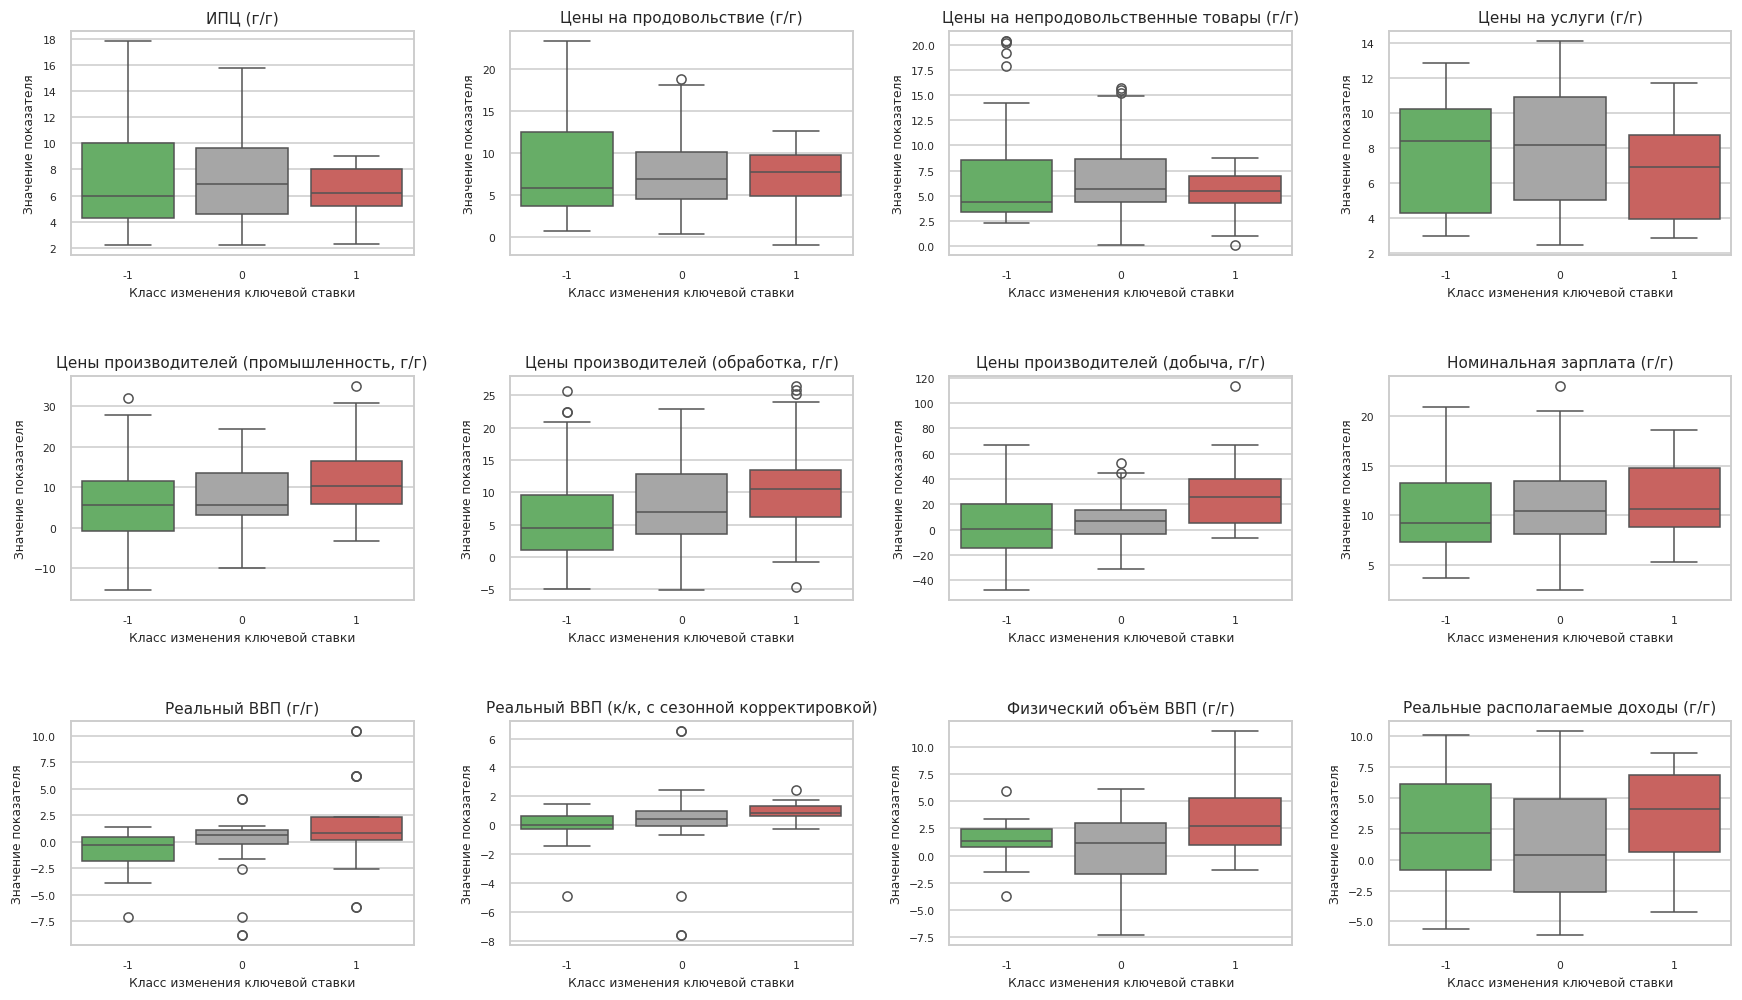

In [19]:
indicator_names = {
    'cpi_mom_index__yoy_chained_pct': 'ИПЦ (г/г)',
    'cpi_food_mom_index__yoy_chained_pct': 'Цены на продовольствие (г/г)',
    'cpi_nonfood_mom_index__yoy_chained_pct': 'Цены на непродовольственные товары (г/г)',
    'cpi_services_mom_index__yoy_chained_pct': 'Цены на услуги (г/г)',
    'ppi_industry_mom_index__yoy_chained_pct': 'Цены производителей (промышленность, г/г)',
    'ppi_manufacturing_mom_index__yoy_chained_pct': 'Цены производителей (обработка, г/г)',
    'ppi_mining_mom_index__yoy_chained_pct': 'Цены производителей (добыча, г/г)',
    'nominal_wages_rub__yoy_pct': 'Номинальная зарплата (г/г)',
    'gdp_real_2021_bln_rub__yoy_change_1q_pp': 'Реальный ВВП (г/г)',
    'gdp_real_2021_sa_bln_rub__qoq_pct': 'Реальный ВВП (к/к, с сезонной корректировкой)',
    'gdp_volume_yoy_index__yoy_pct': 'Физический объём ВВП (г/г)',
    'real_disposable_income_yoy_index__yoy_pct': 'Реальные располагаемые доходы (г/г)'
}

colors = ['#5cb85c', '#a6a6a6', '#d9534f']

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(indicator_names):
    ax = axes[i]
    name = indicator_names[col]

    sns.boxplot(
        data=df,
        x='target_next',
        y=col,
        hue='target_next',
        order=[-1, 0, 1],
        hue_order=[-1, 0, 1],
        palette=colors,
        legend=False,
        ax=ax
    )

    ax.set_title(name, fontsize=10)
    ax.set_xlabel('Класс изменения ключевой ставки', fontsize=8)
    ax.set_ylabel('Значение показателя', fontsize=8)
    ax.tick_params(axis='both', labelsize=7)

for j in range(len(indicator_names), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(h_pad=3, w_pad=2)
plt.show()

Распределения макроэкономических показателей в разрезе классов целевой переменной позволяют выявить различия в экономических условиях, сопровождающих решения об изменении ключевой ставки.

Повышение ставки характеризуется более высокими медианными значениями цен производителей, номинальной заработной платы и показателей ВВП. При снижении ставки наблюдаются относительно низкие значения этих показателей. Для класса сохранения ставки выраженного единого профиля макроэкономических условий не прослеживается.

При этом потребительская инфляция демонстрирует менее однозначные различия между классами.

----


Теперь посмотрим на динамику показателей и ключевой ставки и посчитаем корреляцию Спирмена макроэкономических показателей (с наименьших кол-вом пропусков) с таргетом (-1/0/1).


Для оценки взаимосвязи используется именно корреляция Спирмена, поскольку целевая переменная имеет три упорядоченных класса (снижение, сохранение, повышение ставки). Метод позволяет выявлять не только линейные, но и другие монотонные зависимости, а также менее чувствителен к выбросам, что важно для макроэкономических данных.

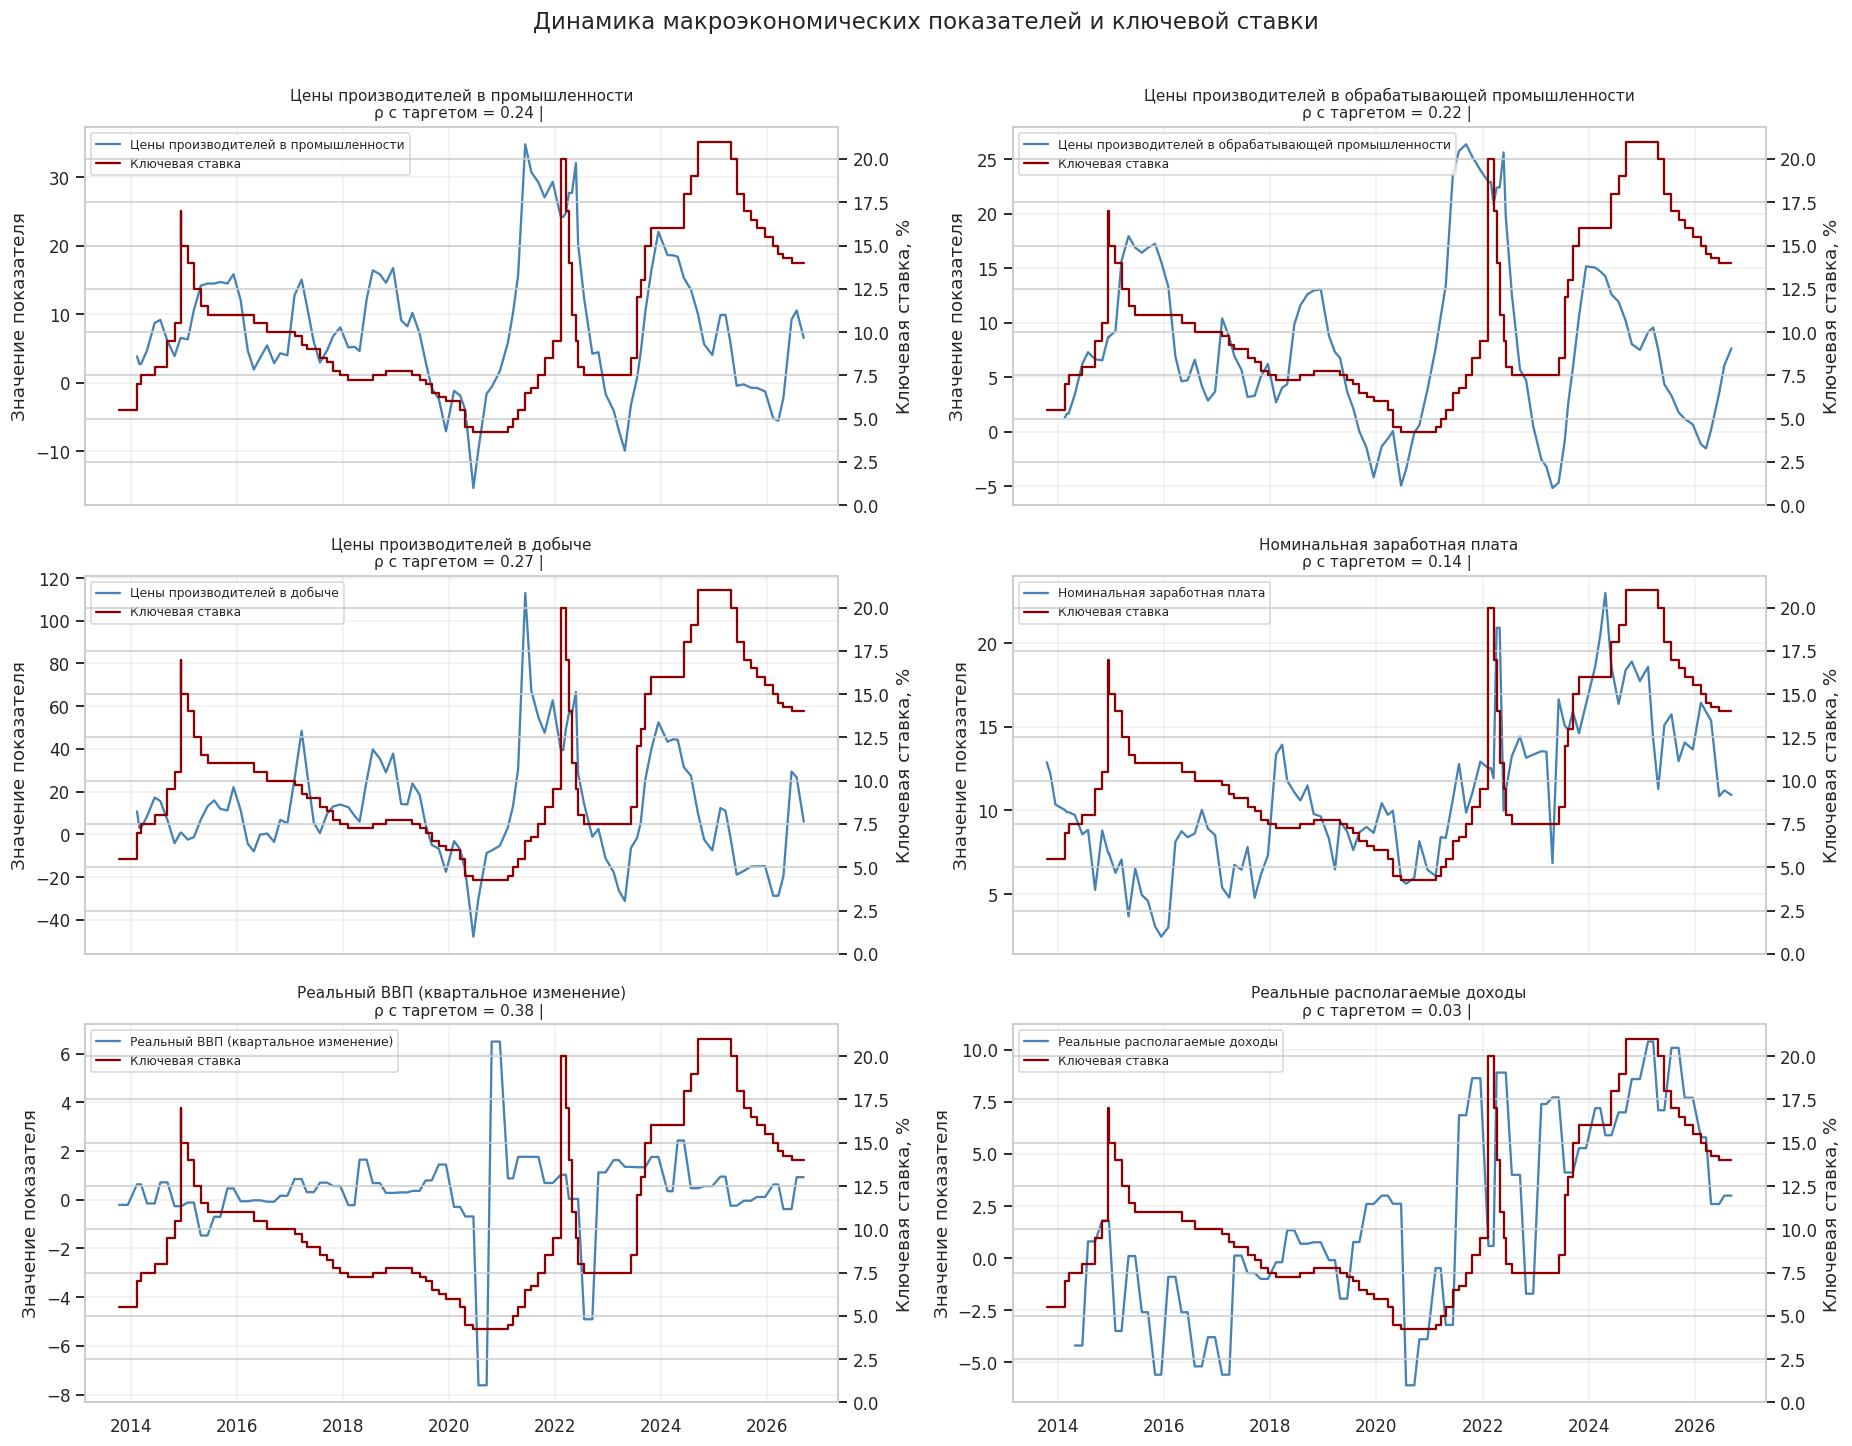

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

indicators = {
    'ppi_industry_mom_index__yoy_chained_pct': 'Цены производителей в промышленности',
    'ppi_manufacturing_mom_index__yoy_chained_pct': 'Цены производителей в обрабатывающей промышленности',
    'ppi_mining_mom_index__yoy_chained_pct': 'Цены производителей в добыче',
    'nominal_wages_rub__yoy_pct': 'Номинальная заработная плата',
    'gdp_real_2021_sa_bln_rub__qoq_pct': 'Реальный ВВП (квартальное изменение)',
    'real_disposable_income_yoy_index__yoy_pct': 'Реальные располагаемые доходы'
}

df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(17, 13),
    sharex=True
)

axes = axes.flatten()

for ax, (col, title) in zip(axes, indicators.items()):

    if col not in df.columns:
        ax.set_visible(False)
        continue

    # Корреляция с таргетом
    data_target = df[[col, 'target_next']].dropna()
    rho_target = data_target[col].corr(
        data_target['target_next'],
        method='spearman'
    )

    sns.lineplot(
        data=df,
        x='date',
        y=col,
        ax=ax,
        color='steelblue',
        linewidth=1.5,
        label=title
    )

    ax.set_title(
        f'{title}\n'
        f'ρ с таргетом = {rho_target:.2f} | ',
        fontsize=10
    )

    ax.set_ylabel('Значение показателя')
    ax.set_xlabel('')
    ax.grid(alpha=0.3)

    ax2 = ax.twinx()

    ax2.step(
        df['date'],
        df['rate_next'],
        color='darkred',
        linewidth=1.5,
        where='post',
        label='Ключевая ставка'
    )

    ax2.set_ylabel('Ключевая ставка, %')
    ax2.set_ylim(bottom=0)

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc='upper left',
        fontsize=8
    )

    sns.despine(ax=ax)

plt.suptitle(
    'Динамика макроэкономических показателей и ключевой ставки',
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

In [21]:
feature_cols = list(indicator_names.keys())

target_corr = (
    df[feature_cols + ['target_next']]
    .corr(method='spearman')['target_next']
    .drop('target_next')
    .reset_index()
)

target_corr.columns = ['Признак', 'Корреляция с таргетом']
target_corr['Название показателя'] = target_corr['Признак'].map(indicator_names)
target_corr['Модуль корреляции'] = target_corr['Корреляция с таргетом'].abs()

target_corr = target_corr.sort_values('Модуль корреляции',ascending=False)

display(
    target_corr[
        ['Название показателя', 'Корреляция с таргетом', 'Модуль корреляции']
    ].round(3)
)


,Название показателя,Корреляция с таргетом,Модуль корреляции
9,"Реальный ВВП (к/к, с сезонной корректировкой)",0.377,0.377
8,Реальный ВВП (г/г),0.370,0.370
6,"Цены производителей (добыча, г/г)",0.272,0.272
4,"Цены производителей (промышленность, г/г)",0.239,0.239
5,"Цены производителей (обработка, г/г)",0.221,0.221
10,Физический объём ВВП (г/г),0.187,0.187
7,Номинальная зарплата (г/г),0.137,0.137
3,Цены на услуги (г/г),-0.108,0.108
2,Цены на непродовольственные товары (г/г),0.060,0.060
0,ИПЦ (г/г),-0.043,0.043


По результатам корреляционного анализа наиболее сильная связь с направлением изменения ключевой ставки наблюдается у показателей ВВП: квартальное изменение реального ВВП (0,377) и его годовое изменение (0,370). Также умеренная положительная корреляция выявлена у индексов цен производителей в добывающей (0,272), промышленной (0,239) и обрабатывающей (0,221) отраслях.

Важно, что значения корреляции невысокие, поэтому ни один из рассмотренных макропоказателей по отдельности не демонстрирует сильной монотонной связи с направлением изменения ключевой ставки.

-----

Теперь посчитаем корреляцию Спирмена между макроэкономическими показателями

In [22]:
feature_cols = list(indicator_names.keys())
corr_matrix = df[feature_cols].corr(method='spearman')
corr_matrix = corr_matrix.rename(
    index=indicator_names,
    columns=indicator_names
)

upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

corr_pairs = (upper_triangle.stack().reset_index())

corr_pairs.columns = ['Показатель 1', 'Показатель 2', 'Корреляция']
corr_pairs['Модуль корреляции'] = corr_pairs['Корреляция'].abs()
corr_pairs = corr_pairs.sort_values('Модуль корреляции',ascending=False)
display(corr_pairs.head(20).round(3))

,Показатель 1,Показатель 2,Корреляция,Модуль корреляции
0,ИПЦ (г/г),Цены на продовольствие (г/г),0.958,0.958
38,"Цены производителей (промышленность, г/г)","Цены производителей (обработка, г/г)",0.948,0.948
39,"Цены производителей (промышленность, г/г)","Цены производителей (добыча, г/г)",0.942,0.942
1,ИПЦ (г/г),Цены на непродовольственные товары (г/г),0.858,0.858
45,"Цены производителей (обработка, г/г)","Цены производителей (добыча, г/г)",0.802,0.802
11,Цены на продовольствие (г/г),Цены на непродовольственные товары (г/г),0.802,0.802
2,ИПЦ (г/г),Цены на услуги (г/г),0.755,0.755
59,Номинальная зарплата (г/г),Реальные располагаемые доходы (г/г),0.720,0.720
60,Реальный ВВП (г/г),"Реальный ВВП (к/к, с сезонной корректировкой)",0.719,0.719
23,Цены на непродовольственные товары (г/г),"Цены производителей (обработка, г/г)",0.670,0.670


По результатам анализа выявлены сильные корреляционные связи между некоторыми макроэкономическими показателями.

Особенно тесно связаны компоненты потребительской инфляции с общим ИПЦ (ρ до 0,958), а также показатели цен производителей в промышленности, добыче и обработке (ρ до 0,948). Это указывает на схожую динамику показателей внутри соответствующих групп.

Также заметна связь между номинальной заработной платой и реальными располагаемыми доходами (ρ = 0,720), а также между различными показателями ВВП (ρ = 0,719).

Высокая корреляция между признаками может приводить к мультиколлинеарности и избыточности информации. Поэтому для дальнейшего моделирования целесообразно рассмотреть исключение одного из сильно коррелирующих показателей, предварительно оценив его связь с целевой переменной и влияние на качество модели.